# Introducción práctica al Procesamiento de Lenguaje Natural
## De texto sin estructura a un pipeline evaluable


### Objetivos
Al terminar este notebook podrá:

- explicar las tareas y dificultades básicas del PLN;
- construir un pipeline de preprocesamiento;
- usar tokenización, stemming, lematización, POS, dependencias y entidades;
- representar documentos con conteos y TF-IDF;
- medir similitud entre textos;
- entrenar y evaluar un clasificador clásico;
- analizar errores, sesgo y límites del sistema.

## Mapa del notebook

| Sección | Tiempo |
|---|---:|
| 1. ¿Qué es PLN? y ambigüedad | 7 min |
| 2. Unidades: corpus, documento, oración, token y tipo | 6 min |
| 3. Normalización y tokenización | 10 min |
| 4. Stopwords, stemming y lematización | 8 min |
| 5. POS, dependencias y entidades | 10 min |
| 6. Bolsa de palabras, TF-IDF y similitud | 12 min |
| 7. Clasificación de texto de extremo a extremo | 20 min |
| 8. Evaluación, errores y sesgo | 5 min |
| 9. Cierre | 2 min |
| **Soluciones de la Extensión B** (al final, antes de las referencias) | — |

## 0. Verificación del entorno

El núcleo usa `re`, `collections`, `pandas`, `scikit-learn`, `nltk` y `spaCy`. El modelo lingüístico completo de spaCy es opcional; si no está instalado, el notebook usa un pipeline básico de español y explica cómo habilitar POS, dependencias, lematización y entidades.

In [1]:
import re
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

print("Python:", sys.version.split()[0])
print("Entorno base cargado correctamente")

Python: 3.12.3
Entorno base cargado correctamente


### spaCy en español

Para habilitar el análisis lingüístico completo, ejecute una vez en una terminal (este entorno es de `uv` y no tiene `pip`, por eso `%pip install` y `python -m spacy download` fallan):

```bash
uv pip install https://github.com/explosion/spacy-models/releases/download/es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl
```

In [2]:
import spacy

try:
    nlp = spacy.load("es_core_news_sm")
    MODELO_SPACY_COMPLETO = True
    print("✅ Modelo es_core_news_sm cargado")
except OSError:
    nlp = spacy.blank("es")
    nlp.add_pipe("sentencizer")
    MODELO_SPACY_COMPLETO = False
    print("⚠️ Se usa spacy.blank('es'). Tokenización disponible; POS, dependencias, lemas y NER requieren es_core_news_sm.")

⚠️ Se usa spacy.blank('es'). Tokenización disponible; POS, dependencias, lemas y NER requieren es_core_news_sm.


# 1. ¿Qué es Procesamiento de Lenguaje Natural? — 7 minutos

El **Procesamiento de Lenguaje Natural (PLN)** estudia métodos computacionales para analizar, representar, comprender o generar lenguaje humano.

### Ejemplos de tareas

- clasificación de documentos;
- análisis de sentimientos;
- extracción de entidades y relaciones;
- búsqueda y recuperación de información;
- traducción automática;
- resumen;
- respuesta a preguntas;
- sistemas conversacionales;
- generación de texto.

### Un pipeline clásico

```text
Texto bruto
   ↓
Limpieza y segmentación
   ↓
Características lingüísticas o estadísticas
   ↓
Representación numérica
   ↓
Modelo o reglas
   ↓
Predicción
   ↓
Evaluación y análisis de errores
```

## El reto central: la ambigüedad

El lenguaje no es una tabla perfectamente estructurada.

- **Léxica:** “banco” puede ser una entidad financiera o un asiento.
- **Sintáctica:** “Vi al estudiante con el telescopio”. ¿Quién tenía el telescopio?
- **Semántica:** “La película estuvo pesada” puede referirse al peso o a una experiencia difícil.
- **Pragmática:** “¿Puedes abrir la ventana?” formalmente es una pregunta de capacidad, pero normalmente es una petición.
- **Referencial:** “María habló con Ana y ella presentó el informe”. ¿Quién presentó?

In [3]:
frases_ambiguas = [
    "Fui al banco a retirar dinero.",
    "Me senté en el banco del parque.",
    "Vi al estudiante con el telescopio.",
    "¿Puedes abrir la ventana?",
]

for i, frase in enumerate(frases_ambiguas, start=1):
    print(i, frase)

1 Fui al banco a retirar dinero.
2 Me senté en el banco del parque.
3 Vi al estudiante con el telescopio.
4 ¿Puedes abrir la ventana?


### Pregunta al grupo

¿Qué información adicional necesitaría un sistema para interpretar correctamente cada frase: palabras cercanas, estructura sintáctica, conocimiento del mundo, intención del hablante o contexto conversacional?

### Respuesta

| Frase | Tipo de ambigüedad | Qué necesita el sistema |
|---|---|---|
| "Fui al banco a retirar dinero." | Léxica | **Palabras cercanas.** "retirar dinero" basta para elegir el sentido de entidad financiera. |
| "Me senté en el banco del parque." | Léxica | **Palabras cercanas.** "me senté" y "parque" apuntan al asiento. |
| "Vi al estudiante con el telescopio." | Sintáctica | **Estructura sintáctica y contexto conversacional.** |
| "¿Puedes abrir la ventana?" | Pragmática | **Intención del hablante y conocimiento del mundo.** |

- **Las dos frases de "banco"** se resuelven con el contexto local: las palabras vecinas son suficientes, y por eso incluso modelos sencillos basados en coocurrencias suelen acertar.
- **La del telescopio** no se resuelve con las palabras vecinas. Hay dos análisis sintácticos válidos: "con el telescopio" modifica a "vi" (yo usé el telescopio) o a "estudiante" (el estudiante lo tenía). La sintaxis muestra las dos opciones, pero para elegir hace falta el contexto previo, por ejemplo si antes se dijo quién tenía un telescopio.
- **La de la ventana** se entiende sin problema en lo literal, pero el significado literal no es el que importa. Formalmente pregunta por una capacidad; para interpretarla como petición el sistema debe reconocer la intención del hablante y saber que, por convención social, esa forma se usa para pedir algo cortésmente.

**Conclusión:** la información necesaria crece de lo local a lo global: palabras vecinas → estructura de la oración → conversación previa → conocimiento del mundo e intención. Las técnicas clásicas de este notebook (BoW, TF-IDF) solo capturan el primer nivel, y por eso los modelos contextuales manejan mejor los demás.

# 2. Unidades fundamentales — 6 minutos

- **Corpus:** colección de documentos.
- **Documento:** unidad textual procesada como un elemento.
- **Oración:** segmento que expresa una unidad gramatical.
- **Token:** ocurrencia concreta de una unidad textual.
- **Tipo:** forma única dentro del vocabulario.
- **Vocabulario:** conjunto de tipos considerados por el sistema.

Ejemplo: en “PLN aprende y PLN transforma”, hay 5 tokens si se separa por espacios, pero 4 tipos después de normalizar.

In [4]:
texto = "PLN aprende y PLN transforma"
tokens = texto.lower().split()
tipos = sorted(set(tokens))

print("Tokens:", tokens)
print("Número de tokens:", len(tokens))
print("Tipos:", tipos)
print("Tamaño del vocabulario:", len(tipos))

Tokens: ['pln', 'aprende', 'y', 'pln', 'transforma']
Número de tokens: 5
Tipos: ['aprende', 'pln', 'transforma', 'y']
Tamaño del vocabulario: 4


## Frecuencia y distribución

Contar tokens es una operación simple, pero útil para explorar un corpus, detectar términos dominantes y verificar calidad.

In [5]:
corpus_pequeno = [
    "La inteligencia artificial procesa lenguaje",
    "El lenguaje expresa conocimiento",
    "La inteligencia artificial aprende de datos",
]

todos_los_tokens = " ".join(corpus_pequeno).lower().split()
frecuencias = Counter(todos_los_tokens)
frecuencias.most_common()

[('la', 2),
 ('inteligencia', 2),
 ('artificial', 2),
 ('lenguaje', 2),
 ('procesa', 1),
 ('el', 1),
 ('expresa', 1),
 ('conocimiento', 1),
 ('aprende', 1),
 ('de', 1),
 ('datos', 1)]

# 3. Normalización y tokenización — 10 minutos

## 3.1 Normalización

Normalizar significa reducir variaciones que no son relevantes para la tarea. No existe una receta universal.

Operaciones comunes:

- convertir a minúsculas;
- normalizar espacios;
- tratar URLs, correos, números o menciones;
- decidir qué hacer con tildes y signos;
- corregir o conservar errores ortográficos;
- preservar información de dominio.

> Una transformación útil para clasificación temática puede destruir información necesaria para reconocimiento de nombres propios o análisis jurídico.

In [6]:
texto_ruidoso = "  Contáctame en Ana.Perez@Ejemplo.com!!! El precio fue $1,250.00.  "

normalizado = texto_ruidoso.strip().lower()
normalizado = re.sub(r"\s+", " ", normalizado)
normalizado_con_marcas = re.sub(r"[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}", "<EMAIL>", normalizado)
normalizado_con_marcas = re.sub(r"\$?[\d,.]+", "<NUM>", normalizado_con_marcas)

print("Original:   ", repr(texto_ruidoso))
print("Normalizado:", normalizado)
print("Con marcas: ", normalizado_con_marcas)

Original:    '  Contáctame en Ana.Perez@Ejemplo.com!!! El precio fue $1,250.00.  '
Normalizado: contáctame en ana.perez@ejemplo.com!!! el precio fue $1,250.00.
Con marcas:  contáctame en <EMAIL>!!! el precio fue <NUM>


## 3.2 Tokenización

Tokenizar es segmentar una cadena en unidades. `split()` es útil para aprender Python, pero no maneja bien puntuación, contracciones, URLs o reglas específicas del idioma.

In [7]:
frase = "¡Hola, Andrés! ¿El curso de PLN empieza a las 6:30 p. m.?"

print("split():")
print(frase.split())

print("\nRegex simple:")
print(re.findall(r"\b\w+(?:[-']\w+)*\b", frase.lower(), flags=re.UNICODE))

print("\nspaCy:")
doc = nlp(frase)
print([token.text for token in doc])

split():
['¡Hola,', 'Andrés!', '¿El', 'curso', 'de', 'PLN', 'empieza', 'a', 'las', '6:30', 'p.', 'm.?']

Regex simple:
['hola', 'andrés', 'el', 'curso', 'de', 'pln', 'empieza', 'a', 'las', '6', '30', 'p', 'm']

spaCy:
['¡', 'Hola', ',', 'Andrés', '!', '¿', 'El', 'curso', 'de', 'PLN', 'empieza', 'a', 'las', '6:30', 'p.', 'm.', '?']


## 3.3 Una función reproducible de preprocesamiento

La función debe hacer explícitas las decisiones. Aquí conservamos letras, números y tildes; convertimos a minúsculas y eliminamos puntuación.

In [8]:
def tokenizar_basico(texto: str) -> list[str]:
    texto = texto.lower().strip()
    return re.findall(r"\b\w+\b", texto, flags=re.UNICODE)

for ejemplo in [
    "¡Excelente curso!",
    "PLN-2026: sesión 1.",
    "Correo: estudiante@universidad.edu",
]:
    print(ejemplo, "->", tokenizar_basico(ejemplo))

¡Excelente curso! -> ['excelente', 'curso']
PLN-2026: sesión 1. -> ['pln', '2026', 'sesión', '1']
Correo: estudiante@universidad.edu -> ['correo', 'estudiante', 'universidad', 'edu']


### Microejercicio

¿Qué cambiaría si la tarea fuera detectar correos electrónicos? ¿Conviene partir `estudiante@universidad.edu` en varias piezas o conservarlo como una unidad?

### Solución

**Conviene conservarlo como una unidad.** Si la tarea es detectar correos, el correo completo *es* la entidad que se busca. `tokenizar_basico` lo parte en `['estudiante', 'universidad', 'edu']` y elimina la `@` y el punto, que son precisamente las señales que lo identifican; después de eso ya no se puede saber que esas tres palabras formaban un correo.

**Qué cambiaría en el pipeline:**

- **Orden de las reglas:** el patrón de correo debe probarse *antes* que el patrón general de palabras, para que tenga prioridad.
- **Puntuación:** ya no se puede eliminar toda; `@`, `.`, `-`, `_` y `+` son parte del token cuando están dentro de un correo.
- **Minúsculas:** siguen siendo aceptables, porque en la práctica los correos no distinguen mayúsculas.
- **Normalización:** depende del objetivo. Para *extraer* correos se conserva el valor; para *clasificar* textos suele bastar con reemplazarlo por una marca como `<EMAIL>` (sección 3.1), que reduce vocabulario y protege datos personales.

La misma idea aplica a URLs, fechas, montos o números de contrato: la tokenización se decide según la tarea.

In [9]:
PATRON_EMAIL = r"[\w.+-]+@[\w.-]+\.\w{2,}"

def tokenizar_con_correos(texto: str) -> list[str]:
    # El patrón de correo va primero: en una alternancia gana la primera opción que coincide.
    return re.findall(rf"{PATRON_EMAIL}|\w+", texto.lower().strip())

for ejemplo in [
    "Correo: estudiante@universidad.edu",
    "Escriba a Ana.Perez@Ejemplo.com.",
    "PLN-2026: sesión 1.",
]:
    print(ejemplo)
    print("  básico:     ", tokenizar_basico(ejemplo))
    print("  con correos:", tokenizar_con_correos(ejemplo))

Correo: estudiante@universidad.edu
  básico:      ['correo', 'estudiante', 'universidad', 'edu']
  con correos: ['correo', 'estudiante@universidad.edu']
Escriba a Ana.Perez@Ejemplo.com.
  básico:      ['escriba', 'a', 'ana', 'perez', 'ejemplo', 'com']
  con correos: ['escriba', 'a', 'ana.perez@ejemplo.com']
PLN-2026: sesión 1.
  básico:      ['pln', '2026', 'sesión', '1']
  con correos: ['pln', '2026', 'sesión', '1']


# 4. Palabras vacías, stemming y lematización — 8 minutos

## 4.1 Palabras vacías (*stopwords*)

Son palabras muy frecuentes que a veces aportan poca discriminación para una tarea concreta. Sin embargo, eliminarlas indiscriminadamente puede borrar negación o estructura.

Ejemplo crítico: “**no** recomiendo este producto”. Si se elimina “no”, cambia el significado.

In [10]:
stopwords_demo = {
    "el", "la", "los", "las", "un", "una", "de", "del", "y", "o", "que", "en", "a", "por", "para"
}

frase = "No recomiendo el servicio porque la respuesta fue lenta"
tokens = tokenizar_basico(frase)
filtrados = [t for t in tokens if t not in stopwords_demo]

print("Tokens:    ", tokens)
print("Filtrados: ", filtrados)

Tokens:     ['no', 'recomiendo', 'el', 'servicio', 'porque', 'la', 'respuesta', 'fue', 'lenta']
Filtrados:  ['no', 'recomiendo', 'servicio', 'porque', 'respuesta', 'fue', 'lenta']


## 4.2 Stemming

El *stemming* aplica reglas para reducir palabras a una raíz aproximada. Puede producir formas que no son palabras válidas.

In [11]:
stemmer = SnowballStemmer("spanish")
palabras = ["correr", "corriendo", "corrió", "corredores", "rápidamente"]

[(palabra, stemmer.stem(palabra)) for palabra in palabras]

[('correr', 'corr'),
 ('corriendo', 'corr'),
 ('corrió', 'corr'),
 ('corredores', 'corredor'),
 ('rápidamente', 'rapid')]

## 4.3 Lematización

La lematización intenta obtener la forma base lingüística considerando información morfológica y, normalmente, la categoría gramatical.

In [12]:
frase = "Los estudiantes analizaron textos y construyeron modelos."
doc = nlp(frase)

if MODELO_SPACY_COMPLETO:
    tabla_lemas = pd.DataFrame([
        {"token": t.text, "lema": t.lemma_, "POS": t.pos_}
        for t in doc if not t.is_space
    ])
    display(tabla_lemas)
else:
    print("Instale es_core_news_sm para observar lemas y POS completos.")
    print([t.text for t in doc])

Instale es_core_news_sm para observar lemas y POS completos.
['Los', 'estudiantes', 'analizaron', 'textos', 'y', 'construyeron', 'modelos', '.']


### Comparación conceptual

| Técnica | Objetivo | Ventaja | Riesgo |
|---|---|---|---|
| Minúsculas | Reducir variantes ortográficas | Simple y rápida | Pierde señal de mayúsculas |
| Stopwords | Reducir términos muy frecuentes | Menor dimensionalidad | Puede borrar negación |
| Stemming | Unificar variantes morfológicas | Rápido | Raíces poco interpretables |
| Lematización | Obtener forma base | Más lingüística | Requiere modelos y contexto |

# 5. POS, dependencias y entidades — 10 minutos

## 5.1 Etiquetado de partes del discurso (POS)

Asigna a cada token una categoría como sustantivo, verbo, adjetivo o adverbio. Es útil para reglas lingüísticas, extracción de patrones y análisis gramatical.

## 5.2 Dependencias sintácticas

Representan relaciones entre palabras: sujeto, objeto, modificador, etc. Cada token depende de otro token —su *head*— mediante una etiqueta.

## 5.3 Entidades nombradas

Identifican menciones de personas, organizaciones, lugares, fechas, cantidades y otras clases definidas por el modelo.

In [13]:
frase = "Microsoft anunció una inversión de 10 millones de dólares en Colombia el 15 de julio."
doc = nlp(frase)

if MODELO_SPACY_COMPLETO:
    analisis = pd.DataFrame([
        {
            "token": t.text,
            "lema": t.lemma_,
            "POS": t.pos_,
            "dependencia": t.dep_,
            "cabeza": t.head.text,
        }
        for t in doc if not t.is_space
    ])
    display(analisis)

    print("Entidades:")
    for ent in doc.ents:
        print(f"- {ent.text!r}: {ent.label_}")
else:
    print("Tokens disponibles con el pipeline básico:")
    print([t.text for t in doc])
    print("Instale es_core_news_sm para POS, dependencias y NER.")

Tokens disponibles con el pipeline básico:
['Microsoft', 'anunció', 'una', 'inversión', 'de', '10', 'millones', 'de', 'dólares', 'en', 'Colombia', 'el', '15', 'de', 'julio', '.']
Instale es_core_news_sm para POS, dependencias y NER.


### Pregunta de interpretación

En un contrato, ¿qué entidades sería útil detectar además de PERSON, ORG y LOC? Posibles respuestas: número de contrato, entidad contratante, proveedor, monto, fecha, obligación, producto, unidad de medida o estado de cumplimiento.

### Respuesta

Las etiquetas genéricas no bastan: `es_core_news_sm` solo reconoce `PER`, `ORG`, `LOC` y `MISC`. En un contrato lo que importa son entidades **de dominio**, y sobre todo el **rol** que cumple cada una.

| Entidad | Ejemplo | Para qué sirve | Cómo detectarla |
|---|---|---|---|
| Número de contrato | `CT-2026-0148` | Identificar y cruzar documentos | Reglas / regex |
| Entidad contratante | "la Universidad" | Saber quién paga y exige | NER + rol |
| Proveedor o contratista | "Suministros Andinos S.A.S." | Saber quién debe cumplir | NER + rol |
| Monto y moneda | `$ 120.000.000 COP` | Control presupuestal | Reglas / regex |
| Fechas | firma, inicio, vencimiento | Alertas de plazos | Reglas + contexto |
| Plazo o duración | "12 meses" | Calcular vencimientos | Reglas |
| Producto o servicio | "licencias de software" | Clasificar el objeto del contrato | Modelo entrenado |
| Cantidad y unidad de medida | "50 unidades" | Verificar entregas | Reglas |
| Obligación | "entregar informes mensuales" | Seguimiento de compromisos | Modelo entrenado |
| Penalidad o garantía | "multa del 10 %" | Gestión de riesgo | Modelo entrenado |
| Estado de cumplimiento | "entregado", "en mora" | Auditoría | Clasificación |

**Tres ideas para la discusión:**

1. **El rol importa más que el tipo.** Contratante y proveedor son ambos `ORG`; una fecha puede ser de firma o de vencimiento. Detectar "es una organización" no alcanza: hay que saber qué papel juega, y eso depende del contexto de la cláusula.
2. **No todo es una entidad corta.** Una obligación o una penalidad es un fragmento largo o una cláusula completa; se aborda mejor como clasificación de oraciones o extracción de relaciones (*quién* debe *qué*, *cuándo*) que como NER clásico.
3. **Se combinan técnicas.** Los patrones regulares (números de contrato, montos, fechas) se resuelven con reglas, como el `EntityRuler` de spaCy; las entidades variables requieren un modelo entrenado con contratos anotados del propio dominio.

# 6. Representación numérica: BoW, TF-IDF y similitud — 12 minutos

Los algoritmos de aprendizaje automático requieren números. Una familia clásica de métodos representa cada documento mediante las palabras que contiene.

## 6.1 Bolsa de palabras (*Bag of Words*)

Construye un vocabulario y cuenta cuántas veces aparece cada término. Ignora gran parte del orden.

In [14]:
documentos = [
    "el modelo procesa texto",
    "el modelo clasifica documentos",
    "el texto contiene palabras",
]

vectorizador_conteo = CountVectorizer()
matriz_conteo = vectorizador_conteo.fit_transform(documentos)

df_conteo = pd.DataFrame(
    matriz_conteo.toarray(),
    columns=vectorizador_conteo.get_feature_names_out(),
    index=["doc_1", "doc_2", "doc_3"],
)
df_conteo

,clasifica,contiene,documentos,el,modelo,palabras,procesa,texto
doc_1,0,0,0,1,1,0,1,1
doc_2,1,0,1,1,1,0,0,0
doc_3,0,1,0,1,0,1,0,1


## 6.2 TF-IDF

TF-IDF aumenta el peso de términos importantes en un documento y reduce el peso de términos frecuentes en muchos documentos.

Una forma común es:

$$
\mathrm{tfidf}(t,d) = \mathrm{tf}(t,d) \times \log\left(\frac{N}{\mathrm{df}(t)}\right)
$$

- `tf(t,d)`: frecuencia del término `t` en el documento `d`.
- `df(t)`: número de documentos que contienen `t`.
- `N`: número total de documentos.

Las implementaciones reales suelen usar suavizado y normalización.

In [15]:
vectorizador_tfidf = TfidfVectorizer()
matriz_tfidf = vectorizador_tfidf.fit_transform(documentos)

df_tfidf = pd.DataFrame(
    np.round(matriz_tfidf.toarray(), 3),
    columns=vectorizador_tfidf.get_feature_names_out(),
    index=["doc_1", "doc_2", "doc_3"],
)
df_tfidf

,clasifica,contiene,documentos,el,modelo,palabras,procesa,texto
doc_1,0.000,0.000,0.000,0.373,0.480,0.000,0.632,0.480
doc_2,0.584,0.000,0.584,0.345,0.445,0.000,0.000,0.000
doc_3,0.000,0.584,0.000,0.345,0.000,0.584,0.000,0.445


## 6.3 Similitud coseno

Mide el ángulo entre dos vectores. Dos documentos con distribuciones parecidas tienen similitud cercana a 1; documentos sin términos compartidos tienden a 0 en una representación TF-IDF clásica.

In [16]:
similitudes = cosine_similarity(matriz_tfidf)

pd.DataFrame(
    np.round(similitudes, 3),
    index=["doc_1", "doc_2", "doc_3"],
    columns=["doc_1", "doc_2", "doc_3"],
)

,doc_1,doc_2,doc_3
doc_1,1.000,0.342,0.342
doc_2,0.342,1.000,0.119
doc_3,0.342,0.119,1.000


## 6.4 Recuperación simple

Añadimos una consulta al mismo espacio vectorial y buscamos el documento con mayor similitud.

In [17]:
base = [
    "cómo restablecer la contraseña de mi cuenta",
    "el pago fue rechazado por la tarjeta",
    "cómo descargar la factura del mes",
    "quiero cambiar mi dirección de correo",
]
consulta = "no recuerdo mi clave para entrar"

vectorizador = TfidfVectorizer(ngram_range=(1, 2))
matriz_base = vectorizador.fit_transform(base)
vector_consulta = vectorizador.transform([consulta])
puntajes = cosine_similarity(vector_consulta, matriz_base).ravel()

ranking = sorted(enumerate(puntajes), key=lambda x: x[1], reverse=True)
for indice, puntaje in ranking:
    print(f"{puntaje:.3f} | {base[indice]}")

0.246 | quiero cambiar mi dirección de correo
0.235 | cómo restablecer la contraseña de mi cuenta
0.000 | el pago fue rechazado por la tarjeta
0.000 | cómo descargar la factura del mes


### Limitación visible

“clave” y “contraseña” son semánticamente cercanas, pero una representación léxica no sabe que son sinónimos salvo que aparezcan en contextos o documentos que conecten ambas formas. Los embeddings y modelos contextuales abordan parte de esta limitación.

# 7. Clasificación de texto de extremo a extremo — 20 minutos

Construiremos un clasificador de opiniones positivas y negativas.

### Pipeline

1. Dataset etiquetado.
2. División entrenamiento/prueba.
3. TF-IDF.
4. Regresión logística.
5. Predicción.
6. Evaluación.
7. Análisis de errores.

> Este dataset es pequeño y pedagógico. No debe interpretarse como evidencia de rendimiento en producción.

In [18]:
datos = [
    ("La clase fue clara y muy útil", "positivo"),
    ("Excelente explicación y buenos ejemplos", "positivo"),
    ("Aprendí mucho con el taller práctico", "positivo"),
    ("El material está completo y bien organizado", "positivo"),
    ("La actividad fue interesante y fácil de seguir", "positivo"),
    ("Muy buena sesión, quiero profundizar", "positivo"),
    ("El profesor explicó con claridad", "positivo"),
    ("Los ejercicios ayudaron a comprender el tema", "positivo"),
    ("La demostración funcionó perfectamente", "positivo"),
    ("El notebook es práctico y comprensible", "positivo"),
    ("La metodología fue dinámica y efectiva", "positivo"),
    ("Quedé satisfecho con la explicación", "positivo"),
    ("El ejemplo de clasificación fue excelente", "positivo"),
    ("La sesión respondió mis preguntas", "positivo"),
    ("El contenido fue relevante para mi proyecto", "positivo"),
    ("La guía está muy bien estructurada", "positivo"),
    ("La práctica facilitó el aprendizaje", "positivo"),
    ("Los conceptos quedaron claros", "positivo"),
    ("La explicación fue confusa y desordenada", "negativo"),
    ("No entendí el ejercicio", "negativo"),
    ("El material está incompleto", "negativo"),
    ("La sesión fue aburrida y poco útil", "negativo"),
    ("Faltaron ejemplos prácticos", "negativo"),
    ("El ritmo fue demasiado rápido", "negativo"),
    ("La actividad no funcionó", "negativo"),
    ("La explicación dejó muchas dudas", "negativo"),
    ("El notebook tiene errores", "negativo"),
    ("El contenido fue irrelevante para mi proyecto", "negativo"),
    ("No recomiendo esta clase", "negativo"),
    ("La metodología fue difícil de seguir", "negativo"),
    ("El ejercicio fue frustrante", "negativo"),
    ("La guía está mal organizada", "negativo"),
    ("La práctica no ayudó a aprender", "negativo"),
    ("Los conceptos no quedaron claros", "negativo"),
    ("La demostración falló varias veces", "negativo"),
    ("Quedé insatisfecho con la sesión", "negativo"),
]

df = pd.DataFrame(datos, columns=["texto", "etiqueta"])
display(df.head())
print(df["etiqueta"].value_counts())

,texto,etiqueta
0,La clase fue clara y muy útil,positivo
1,Excelente explicación y buenos ejemplos,positivo
2,Aprendí mucho con el taller práctico,positivo
3,El material está completo y bien organizado,positivo
4,La actividad fue interesante y fácil de seguir,positivo


etiqueta
positivo    18
negativo    18
Name: count, dtype: int64


## 7.1 Separación de entrenamiento y prueba

El modelo aprende con el conjunto de entrenamiento. La evaluación debe usar ejemplos no vistos durante el ajuste.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    df["texto"],
    df["etiqueta"],
    test_size=0.30,
    random_state=42,
    stratify=df["etiqueta"],
)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))
print(y_test.value_counts())

Entrenamiento: 25
Prueba: 11
etiqueta
negativo    6
positivo    5
Name: count, dtype: int64


## 7.2 Pipeline de scikit-learn

El pipeline garantiza que el vectorizador se ajusta únicamente con los datos de entrenamiento y que la misma transformación se aplica a datos nuevos.

In [20]:
modelo = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1)),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

print("Modelo entrenado")

Modelo entrenado


## 7.3 Evaluación

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** entre los ejemplos predichos como una clase, cuántos eran correctos.
- **Recall:** entre los ejemplos reales de una clase, cuántos recuperó el modelo.
- **F1:** media armónica de precision y recall.

In [21]:
exactitud = accuracy_score(y_test, predicciones)
print(f"Accuracy: {exactitud:.3f}\n")
print(classification_report(y_test, predicciones, zero_division=0))

Accuracy: 0.545

              precision    recall  f1-score   support

    negativo       0.60      0.50      0.55         6
    positivo       0.50      0.60      0.55         5

    accuracy                           0.55        11
   macro avg       0.55      0.55      0.55        11
weighted avg       0.55      0.55      0.55        11



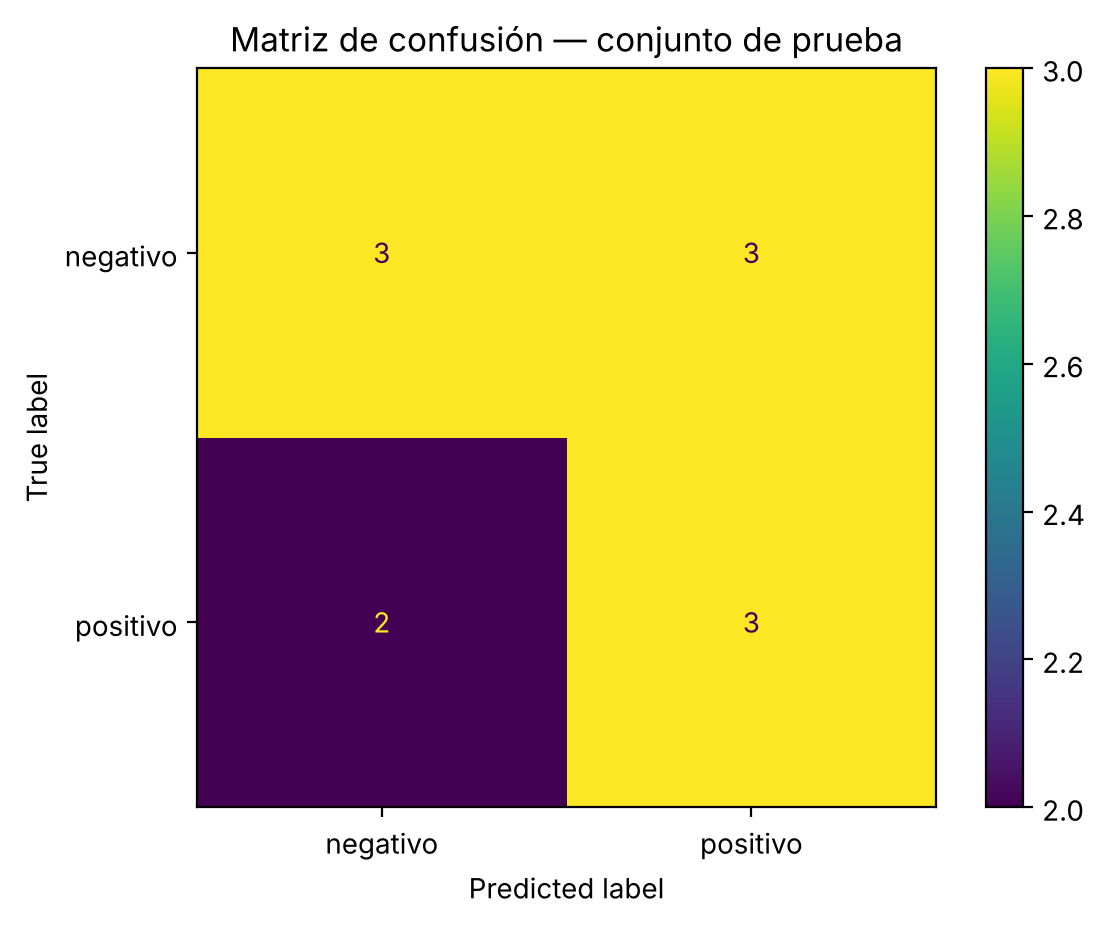

In [22]:
ConfusionMatrixDisplay.from_predictions(y_test, predicciones)
plt.title("Matriz de confusión — conjunto de prueba")
plt.show()

## 7.4 Inspección de predicciones

In [23]:
resultados_prueba = pd.DataFrame({
    "texto": X_test.values,
    "real": y_test.values,
    "predicción": predicciones,
})
resultados_prueba["correcta"] = resultados_prueba["real"] == resultados_prueba["predicción"]
resultados_prueba

,texto,real,predicción,correcta
0,La actividad no funcionó,negativo,positivo,False
1,El ejercicio fue frustrante,negativo,negativo,True
2,"Muy buena sesión, quiero profundizar",positivo,positivo,True
3,Quedé satisfecho con la explicación,positivo,negativo,False
4,El notebook es práctico y comprensible,positivo,negativo,False
5,Faltaron ejemplos prácticos,negativo,positivo,False
6,No recomiendo esta clase,negativo,negativo,True
7,La clase fue clara y muy útil,positivo,positivo,True
8,La explicación dejó muchas dudas,negativo,negativo,True
9,Excelente explicación y buenos ejemplos,positivo,positivo,True


## 7.5 Predicción sobre ejemplos nuevos

Las probabilidades son confianza del modelo dentro de sus supuestos, no una garantía de verdad.

In [24]:
nuevos = [
    "La sesión fue útil aunque un poco rápida",
    "No fue una mala explicación",
    "El notebook parece completo",
    "Esperaba mucho más del ejercicio",
]

pred = modelo.predict(nuevos)
prob = modelo.predict_proba(nuevos)
clases = modelo.named_steps["clasificador"].classes_

for texto_nuevo, etiqueta, probabilidades in zip(nuevos, pred, prob):
    detalle = {clase: round(float(p), 3) for clase, p in zip(clases, probabilidades)}
    print(f"{etiqueta:8} {detalle} | {texto_nuevo}")

negativo {'negativo': 0.556, 'positivo': 0.444} | La sesión fue útil aunque un poco rápida
negativo {'negativo': 0.56, 'positivo': 0.44} | No fue una mala explicación
negativo {'negativo': 0.502, 'positivo': 0.498} | El notebook parece completo
positivo {'negativo': 0.485, 'positivo': 0.515} | Esperaba mucho más del ejercicio


## 7.6 ¿Qué términos usa el modelo?

En regresión logística, coeficientes positivos y negativos permiten inspeccionar qué características empujan la decisión hacia una clase. Esta interpretación es local al dataset y al modelo.

In [25]:
vectorizador = modelo.named_steps["tfidf"]
clasificador = modelo.named_steps["clasificador"]
terminos = vectorizador.get_feature_names_out()
coeficientes = clasificador.coef_[0]

mas_positivos = np.argsort(coeficientes)[-10:][::-1]
mas_negativos = np.argsort(coeficientes)[:10]

print("Características asociadas con", clasificador.classes_[1])
for i in mas_positivos:
    print(f"{terminos[i]:25} {coeficientes[i]: .3f}")

print("\nCaracterísticas asociadas con", clasificador.classes_[0])
for i in mas_negativos:
    print(f"{terminos[i]:25} {coeficientes[i]: .3f}")

Características asociadas con positivo
bien                       0.246
conceptos quedaron         0.188
funcionó                   0.169
funcionó perfectamente     0.169
perfectamente              0.169
demostración funcionó      0.169
efectiva                   0.162
fue dinámica               0.162
dinámica efectiva          0.162
dinámica                   0.162

Características asociadas con negativo
no                        -0.305
está incompleto           -0.203
incompleto                -0.203
conceptos no              -0.176
no quedaron               -0.176
errores                   -0.170
notebook                  -0.170
el notebook               -0.170
tiene errores             -0.170
notebook tiene            -0.170


# 8. Evaluación responsable, errores y sesgo — 5 minutos

Un sistema de PLN puede fallar aunque el código sea correcto.

### Preguntas mínimas antes de desplegar

1. **Representatividad:** ¿el dataset cubre usuarios, dialectos y dominios reales?
2. **Etiquetas:** ¿quién etiquetó y con qué acuerdo?
3. **Desbalance:** ¿hay clases minoritarias importantes?
4. **Costo del error:** ¿es peor un falso positivo o un falso negativo?
5. **Cambio temporal:** ¿el lenguaje o el proceso cambia con el tiempo?
6. **Privacidad:** ¿hay datos personales o sensibles?
7. **Explicabilidad:** ¿podemos justificar una predicción?
8. **Supervisión humana:** ¿qué decisiones no deben automatizarse por completo?

## Mini análisis de errores

Revise manualmente los errores del conjunto de prueba y los ejemplos nuevos. Busque:

- negación;
- ironía;
- mezcla de opinión positiva y negativa;
- palabras no vistas;
- dependencia del dominio;
- etiquetas discutibles.

In [26]:
errores = resultados_prueba[~resultados_prueba["correcta"]]
if len(errores) == 0:
    print("No hubo errores en esta partición pequeña. Eso no demuestra generalización.")
else:
    display(errores)

,texto,real,predicción,correcta
0,La actividad no funcionó,negativo,positivo,False
3,Quedé satisfecho con la explicación,positivo,negativo,False
4,El notebook es práctico y comprensible,positivo,negativo,False
5,Faltaron ejemplos prácticos,negativo,positivo,False
10,La práctica no ayudó a aprender,negativo,positivo,False


# 9. Cierre — 2 minutos

## Lo que construimos

```text
Texto
  → normalización y tokenización
  → rasgos lingüísticos
  → TF-IDF
  → clasificador
  → métricas
  → análisis de errores y riesgos
```

## Idea clave

PLN no es solamente entrenar un modelo. Es diseñar y evaluar un sistema completo donde cada decisión de datos, representación, algoritmo y métrica afecta el resultado.

# Extensión A — De técnicas clásicas a embeddings y LLMs

- **BoW/TF-IDF:** representación dispersa, interpretable y dependiente del vocabulario.
- **Word embeddings:** vectores densos que capturan regularidades distribucionales.
- **Embeddings contextuales:** una palabra puede tener diferentes vectores según la oración.
- **Transformers y LLMs:** modelan dependencias de largo alcance y permiten transferencia entre tareas.

Las técnicas clásicas siguen siendo valiosas cuando hay pocos datos, restricciones de cómputo, necesidad de interpretabilidad o dominios muy controlados.

# Extensión B — Ejercicios autónomos

1. Cambie el preprocesamiento para conservar negaciones.
2. Compare unigramas contra unigramas + bigramas.
3. Sustituya regresión logística por `MultinomialNB`.
4. Use validación cruzada.
5. Añada una clase neutral y observe el impacto.
6. Cree un conjunto de prueba con ejemplos ambiguos.
7. Diseñe métricas distintas si el costo de falsos negativos es mayor.
8. Compare similitud TF-IDF con embeddings de oraciones.

> ✅ **Las soluciones de estos ocho ejercicios están en las celdas siguientes**, en la sección *Soluciones de la Extensión B*.

# Soluciones de la Extensión B

Esta sección resuelve los ocho ejercicios autónomos. Todas las soluciones reutilizan `df`, `X_train`, `X_test`, `y_train`, `y_test` y `nuevos`, definidos en la sección 7, así que **ejecute primero el notebook completo**.

Para que las comparaciones sean justas, cada variante se evalúa de dos formas:

- **Partición del notebook** (`random_state=42`, 11 frases de prueba), para comparar con el resultado original.
- **Validación cruzada estratificada de 5 pliegues** sobre las 36 frases, que usa todos los datos para evaluar y muestra cuánto varía el resultado.

> Spoiler del ejercicio 4: con 36 frases, la partición única es tan inestable que casi cualquier diferencia entre variantes es ruido. Lea las conclusiones de cada ejercicio con esa advertencia.

In [27]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, LeaveOneOut
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score, recall_score, precision_score, fbeta_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 160)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def crear_modelo(clasificador=None, ngram_range=(1, 2), preprocessor=None, stop_words=None):
    """Mismo pipeline de la sección 7.2, con piezas intercambiables."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=ngram_range, min_df=1,
                                  preprocessor=preprocessor, stop_words=stop_words)),
        ("clasificador", clasificador if clasificador is not None
                         else LogisticRegression(max_iter=1000, random_state=42)),
    ])

def evaluar(nombre, modelo_):
    """Evalúa una variante en la partición del notebook y con validación cruzada."""
    m = clone(modelo_).fit(X_train, y_train)
    pred = m.predict(X_test)
    cv = cross_val_score(clone(modelo_), df["texto"], df["etiqueta"], cv=cv5)
    return {
        "variante": nombre,
        "accuracy_prueba": round(accuracy_score(y_test, pred), 3),
        "f1_macro_prueba": round(f1_score(y_test, pred, average="macro"), 3),
        "errores_prueba": int((pred != y_test.values).sum()),
        "cv_media": round(cv.mean(), 3),
        "cv_desv": round(cv.std(), 3),
        "vocabulario": len(m.named_steps["tfidf"].vocabulary_),
    }

resultados = [evaluar("Base (notebook)", crear_modelo())]
pd.DataFrame(resultados)

,variante,accuracy_prueba,f1_macro_prueba,errores_prueba,cv_media,cv_desv,vocabulario
0,Base (notebook),0.545,0.545,5,0.389,0.166,170


## Ejercicio 1 — Conservar negaciones

**Objetivo:** que el modelo distinga “funcionó” de “no funcionó”.

**Enfoque:** el modelo base ya conserva la palabra “no” (la lista de stopwords de la sección 4.1 no la incluye), pero la regresión logística suma pesos palabra por palabra: “no” resta y “funcionó” suma por separado. Probamos tres variantes:

1. **Eliminar “no” como stopword** (lo que pasaría con muchas listas estándar), para medir el daño.
2. **Marcar el ámbito de la negación:** cada palabra que sigue a una negación se reescribe como `NEG_palabra` hasta el final de la frase. Así “funcionó” y “NEG_funcionó” son características distintas.
3. **Marcar solo la palabra siguiente** a la negación (ámbito corto).

In [28]:
NEGACIONES = {"no", "nunca", "ni", "tampoco", "jamás", "sin"}

def marcar_negacion(texto: str) -> str:
    """Prefija NEG_ a todas las palabras posteriores a una negación (hasta el final de la frase)."""
    salida, negando = [], False
    for t in re.findall(r"\w+", texto.lower()):
        if t in NEGACIONES:
            salida.append(t)
            negando = True
        else:
            salida.append("NEG_" + t if negando else t)
    return " ".join(salida)

def marcar_negacion_corta(texto: str) -> str:
    """Prefija NEG_ solo a la palabra inmediatamente posterior a una negación."""
    toks = re.findall(r"\w+", texto.lower())
    return " ".join("NEG_" + t if i > 0 and toks[i - 1] in NEGACIONES else t
                    for i, t in enumerate(toks))

for frase in ["La actividad no funcionó", "No fue una mala explicación", "Los conceptos no quedaron claros"]:
    print(f"{frase!r:40} -> {marcar_negacion(frase)!r}")
    print(f"{'':40}    {marcar_negacion_corta(frase)!r} (ámbito corto)")

'La actividad no funcionó'               -> 'la actividad no NEG_funcionó'
                                            'la actividad no NEG_funcionó' (ámbito corto)
'No fue una mala explicación'            -> 'no NEG_fue NEG_una NEG_mala NEG_explicación'
                                            'no NEG_fue una mala explicación' (ámbito corto)
'Los conceptos no quedaron claros'       -> 'los conceptos no NEG_quedaron NEG_claros'
                                            'los conceptos no NEG_quedaron claros' (ámbito corto)


In [29]:
stopwords_con_no = sorted(stopwords_demo | {"no"})

variantes_neg = {
    "Stopwords con 'no' (dañina)": crear_modelo(stop_words=stopwords_con_no),
    "Marcar negación (hasta el final)": crear_modelo(preprocessor=marcar_negacion),
    "Marcar negación (1 palabra)": crear_modelo(preprocessor=marcar_negacion_corta),
}
tabla_neg = pd.DataFrame(resultados + [evaluar(k, v) for k, v in variantes_neg.items()])
display(tabla_neg)

# Predicciones sobre las frases de prueba que contienen "no" y sobre los ejemplos nuevos
frases_neg = [t for t in X_test if re.search(r"\bno\b", t.lower())] + nuevos
comparacion = pd.DataFrame({"texto": frases_neg})
for nombre, m in [("base", crear_modelo())] + list(variantes_neg.items()):
    comparacion[nombre] = clone(m).fit(X_train, y_train).predict(frases_neg)
comparacion

,variante,accuracy_prueba,f1_macro_prueba,errores_prueba,cv_media,cv_desv,vocabulario
0,Base (notebook),0.545,0.545,5,0.389,0.166,170
1,Stopwords con 'no' (dañina),0.545,0.530,5,0.254,0.111,139
2,Marcar negación (hasta el final),0.455,0.450,6,0.361,0.143,174
3,Marcar negación (1 palabra),0.545,0.545,5,0.389,0.166,172


,texto,base,Stopwords con 'no' (dañina),Marcar negación (hasta el final),Marcar negación (1 palabra)
0,La actividad no funcionó,positivo,positivo,positivo,positivo
1,No recomiendo esta clase,negativo,positivo,negativo,negativo
2,La práctica no ayudó a aprender,positivo,positivo,positivo,positivo
3,La sesión fue útil aunque un poco rápida,negativo,negativo,negativo,negativo
4,No fue una mala explicación,negativo,negativo,negativo,negativo
5,El notebook parece completo,negativo,positivo,positivo,negativo
6,Esperaba mucho más del ejercicio,positivo,positivo,positivo,positivo


### Interpretación

- **Eliminar “no” sí hace daño, y se ve:** “No recomiendo esta clase”, que el modelo base acertaba, pasa a ser un error, y la validación cruzada cae a su peor valor de la tabla.
- **Las dos frases negadas que fallaban siguen fallando con todas las variantes:** “La actividad no funcionó” y “La práctica no ayudó a aprender”.
- **Marcar la negación no mejora este dataset.** Con 25 frases de entrenamiento, `NEG_funcionó` o `NEG_ayudó` nunca aparecen al entrenar, así que el modelo no tiene ningún peso aprendido para ellas: la característica existe, pero vale 0 para la decisión. El ámbito largo incluso empeora un poco, porque reparte las pocas negaciones del entrenamiento en muchas características nuevas que aparecen una sola vez.
- **Lección:** un cambio de preprocesamiento solo ayuda si los datos de entrenamiento contienen ejemplos de lo que se quiere capturar. Para que la marca de negación funcione se necesitan muchas frases negadas etiquetadas. La técnica es correcta; lo que falta son datos.

## Ejercicio 2 — Unigramas contra unigramas + bigramas

**Objetivo:** ver si los pares de palabras aportan información. Basta cambiar `ngram_range=(1, 2)` por `(1, 1)`.

In [30]:
tabla_ngramas = pd.DataFrame(resultados + [evaluar("Solo unigramas (1,1)", crear_modelo(ngram_range=(1, 1)))])
display(tabla_ngramas)

m_uni = crear_modelo(ngram_range=(1, 1)).fit(X_train, y_train)
terminos_uni = m_uni.named_steps["tfidf"].get_feature_names_out()
coef_uni = m_uni.named_steps["clasificador"].coef_[0]
orden = np.argsort(coef_uni)
print("Unigramas más positivos:", [(terminos_uni[i], round(coef_uni[i], 3)) for i in orden[-6:][::-1]])
print("Unigramas más negativos:", [(terminos_uni[i], round(coef_uni[i], 3)) for i in orden[:6]])

,variante,accuracy_prueba,f1_macro_prueba,errores_prueba,cv_media,cv_desv,vocabulario
0,Base (notebook),0.545,0.545,5,0.389,0.166,170
1,"Solo unigramas (1,1)",0.727,0.727,3,0.361,0.143,78


Unigramas más positivos: [('bien', np.float64(0.347)), ('perfectamente', np.float64(0.236)), ('funcionó', np.float64(0.236)), ('efectiva', np.float64(0.235)), ('dinámica', np.float64(0.235)), ('relevante', np.float64(0.214))]
Unigramas más negativos: [('no', np.float64(-0.432)), ('incompleto', np.float64(-0.288)), ('difícil', np.float64(-0.249)), ('insatisfecho', np.float64(-0.239)), ('quedé', np.float64(-0.239)), ('notebook', np.float64(-0.239))]


### Interpretación

- En la **partición del notebook**, los unigramas parecen ganar con claridad (0,727 frente a 0,545) y el vocabulario baja de 170 a 78 términos. La explicación plausible: con tan pocos datos, casi todos los bigramas aparecen una sola vez y le quitan peso relativo a las palabras sueltas, que son las que se repiten.
- Pero en **validación cruzada** la diferencia desaparece (0,361 frente a 0,389, con desviaciones de ±0,14 a ±0,17). Una mejora de 2 frases sobre 11 no es una mejora demostrada.
- **Lección:** los bigramas tienen sentido cuando hay datos suficientes para que se repitan (“no funcionó”, “muy útil”). Aquí no los hay, y una sola partición puede contar una historia falsa.

## Ejercicio 3 — `MultinomialNB` en lugar de regresión logística

**Naive Bayes multinomial** estima, para cada clase, la probabilidad de cada término, y supone que los términos son independientes entre sí dada la clase. Es rápido y suele funcionar bien con textos cortos y pocos datos. Basta cambiar el segundo paso del `Pipeline`.

In [31]:
tabla_nb = pd.DataFrame(resultados + [
    evaluar("MultinomialNB (1,2)", crear_modelo(MultinomialNB())),
    evaluar("MultinomialNB (1,1)", crear_modelo(MultinomialNB(), ngram_range=(1, 1))),
    evaluar("Regresión logística (1,1)", crear_modelo(ngram_range=(1, 1))),
])
display(tabla_nb)

m_nb = crear_modelo(MultinomialNB()).fit(X_train, y_train)
pd.DataFrame({"texto": nuevos, "pred_logistica": modelo.predict(nuevos), "pred_naive_bayes": m_nb.predict(nuevos),
              "P(pos) NB": m_nb.predict_proba(nuevos)[:, 1].round(3)})

,variante,accuracy_prueba,f1_macro_prueba,errores_prueba,cv_media,cv_desv,vocabulario
0,Base (notebook),0.545,0.545,5,0.389,0.166,170
1,"MultinomialNB (1,2)",0.455,0.450,6,0.389,0.166,170
2,"MultinomialNB (1,1)",0.636,0.633,4,0.332,0.190,78
3,"Regresión logística (1,1)",0.727,0.727,3,0.361,0.143,78


,texto,pred_logistica,pred_naive_bayes,P(pos) NB
0,La sesión fue útil aunque un poco rápida,negativo,negativo,0.366
1,No fue una mala explicación,negativo,negativo,0.368
2,El notebook parece completo,negativo,negativo,0.462
3,Esperaba mucho más del ejercicio,positivo,positivo,0.500


### Interpretación

- En la partición del notebook, Naive Bayes con bigramas comete un error más que la regresión logística (0,455); con unigramas mejora (0,636).
- En validación cruzada, las cuatro variantes quedan en el mismo rango (0,33 a 0,39). **Ningún clasificador gana**: el cuello de botella no es el algoritmo, sino los datos.
- Diferencia conceptual útil: la regresión logística aprende pesos que compiten entre sí (si dos palabras siempre van juntas, se reparten el peso); Naive Bayes cuenta cada palabra por separado. Con más datos, la regresión logística suele ganar; con muy pocos, Naive Bayes suele ser más estable.

## Ejercicio 4 — Validación cruzada

**Objetivo:** medir el rendimiento con todos los datos y ver cuánto depende de la partición.

Se hacen tres cosas: (a) validación cruzada de 5 pliegues, (b) repetir la partición 70/30 con 30 semillas distintas y (c) *leave-one-out*: entrenar con 35 frases y probar con la restante, 36 veces.

5 pliegues: [0.375 0.571 0.286 0.143 0.571] -> media 0.389 ± 0.166


30 particiones: media 0.324, desv 0.132, mín 0.000, máx 0.636


Leave-one-out: 0.222


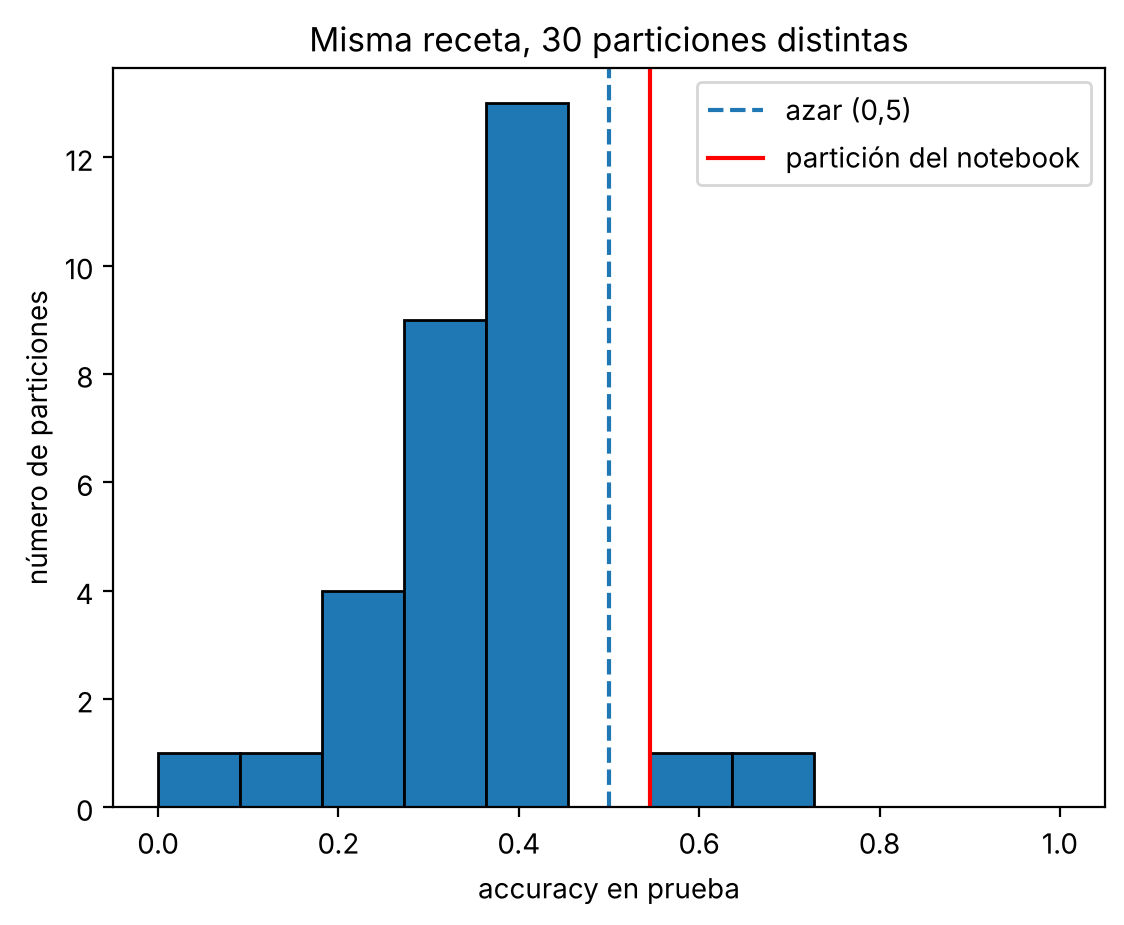

In [32]:
# (a) 5 pliegues estratificados
puntajes = cross_val_score(crear_modelo(), df["texto"], df["etiqueta"], cv=cv5)
print("5 pliegues:", puntajes.round(3), "-> media", round(puntajes.mean(), 3), "±", round(puntajes.std(), 3))

# (b) 30 particiones 70/30 distintas
exactitudes = []
for semilla in range(30):
    Xa, Xb, ya, yb = train_test_split(df["texto"], df["etiqueta"], test_size=0.30,
                                      random_state=semilla, stratify=df["etiqueta"])
    exactitudes.append(accuracy_score(yb, crear_modelo().fit(Xa, ya).predict(Xb)))
exactitudes = np.array(exactitudes)
print(f"30 particiones: media {exactitudes.mean():.3f}, desv {exactitudes.std():.3f}, "
      f"mín {exactitudes.min():.3f}, máx {exactitudes.max():.3f}")

# (c) leave-one-out
pred_loo = cross_val_predict(crear_modelo(), df["texto"], df["etiqueta"], cv=LeaveOneOut())
print("Leave-one-out:", round(accuracy_score(df["etiqueta"], pred_loo), 3))

plt.hist(exactitudes, bins=np.arange(0, 1.05, 1 / 11), edgecolor="black")
plt.axvline(0.5, linestyle="--", label="azar (0,5)")
plt.axvline(0.545, color="red", label="partición del notebook")
plt.xlabel("accuracy en prueba"); plt.ylabel("número de particiones"); plt.legend()
plt.title("Misma receta, 30 particiones distintas")
plt.show()

El resultado es **peor que el azar** de forma sistemática, y con *leave-one-out* es aún peor. Eso no es mala suerte: tiene una causa. La siguiente celda la busca comparando cada frase con su vecina más parecida del dataset.

In [33]:
vect = TfidfVectorizer().fit(df["texto"])
similitud = cosine_similarity(vect.transform(df["texto"]))
np.fill_diagonal(similitud, -1)
vecino = similitud.argmax(axis=1)

gemelos = pd.DataFrame({
    "texto": df["texto"],
    "etiqueta": df["etiqueta"],
    "frase más parecida": df["texto"].values[vecino],
    "su etiqueta": df["etiqueta"].values[vecino],
    "similitud": similitud[np.arange(len(df)), vecino].round(2),
})
opuestas = (gemelos["etiqueta"] != gemelos["su etiqueta"])
print(f"Frases cuya vecina más parecida tiene la etiqueta OPUESTA: {opuestas.sum()} de {len(df)}")

errores_loo = pred_loo != df["etiqueta"].values
print(f"Errores en leave-one-out: {errores_loo.sum()}; de ellos con vecina opuesta: {(errores_loo & opuestas).sum()}")
gemelos.sort_values("similitud", ascending=False).head(10)

Frases cuya vecina más parecida tiene la etiqueta OPUESTA: 28 de 36
Errores en leave-one-out: 28; de ellos con vecina opuesta: 25


,texto,etiqueta,frase más parecida,su etiqueta,similitud
33,Los conceptos no quedaron claros,negativo,Los conceptos quedaron claros,positivo,0.93
17,Los conceptos quedaron claros,positivo,Los conceptos no quedaron claros,negativo,0.93
14,El contenido fue relevante para mi proyecto,positivo,El contenido fue irrelevante para mi proyecto,negativo,0.79
27,El contenido fue irrelevante para mi proyecto,negativo,El contenido fue relevante para mi proyecto,positivo,0.79
11,Quedé satisfecho con la explicación,positivo,Quedé insatisfecho con la sesión,negativo,0.50
35,Quedé insatisfecho con la sesión,negativo,Quedé satisfecho con la explicación,positivo,0.50
20,El material está incompleto,negativo,El material está completo y bien organizado,positivo,0.48
3,El material está completo y bien organizado,positivo,El material está incompleto,negativo,0.48
29,La metodología fue difícil de seguir,negativo,La actividad fue interesante y fácil de seguir,positivo,0.46
4,La actividad fue interesante y fácil de seguir,positivo,La metodología fue difícil de seguir,negativo,0.46


### Interpretación

- **El dataset está construido con pares mínimos:** “El material está completo…” / “El material está incompleto”, “Los conceptos quedaron claros” / “Los conceptos no quedaron claros”, “El contenido fue relevante…” / “…irrelevante…”. En 28 de las 36 frases, la frase más parecida tiene la etiqueta contraria.
- Cuando una frase cae en prueba y su gemela en entrenamiento, las palabras que comparten (“material”, “conceptos quedaron”, “contenido fue”) llevan el peso de la etiqueta de la gemela, es decir, la contraria. Por eso el modelo acierta **menos** que el azar. Con *leave-one-out* la gemela siempre está en entrenamiento, y la accuracy se hunde aún más.
- La relación con los errores es directa: de los 28 errores de *leave-one-out*, 25 son frases cuya vecina más parecida tiene la etiqueta opuesta.
- Los 5 pliegues van de 0,143 a 0,571: el mismo modelo parece “malo” o “aceptable” según qué frases caigan juntas.
- La accuracy de 0,545 del notebook fue una partición afortunada: en 30 particiones, la media es 0,32 y el rango va de 0 a 0,64.
- **Lección principal de toda la extensión:** con datos tan pequeños, la validación cruzada no es opcional. Una sola partición puede hacer creer que un modelo funciona, o que una variante es mejor, cuando todo es ruido. El dataset sirve para enseñar el pipeline, no para medir rendimiento (como advierte la sección 7).

## Ejercicio 5 — Añadir una clase neutral

**Objetivo:** ver qué pasa cuando no todo texto es opinión. Se añaden 12 frases neutrales, **escritas para este ejercicio** (no vienen del dataset original), que hablan de la clase sin valorarla. Se evalúa con validación cruzada (`cross_val_predict`) para usar las 48 frases.

In [34]:
neutros = [
    "La clase empezó a las seis de la tarde",
    "El notebook tiene nueve secciones",
    "La sesión duró ochenta minutos",
    "El profesor compartió el enlace del material",
    "El taller se revisará la próxima semana",
    "La actividad se hizo en grupos de tres",
    "El ejercicio usa scikit-learn y pandas",
    "La guía tiene diez páginas",
    "Los conceptos se verán en la próxima clase",
    "El material está en la carpeta del curso",
    "La demostración se hizo con Python",
    "El contenido incluye ejemplos en español",
]
df3 = pd.concat([df, pd.DataFrame({"texto": neutros, "etiqueta": "neutral"})], ignore_index=True)
print(df3["etiqueta"].value_counts(), "\n")

pred3 = cross_val_predict(crear_modelo(), df3["texto"], df3["etiqueta"], cv=cv5)
print(f"Accuracy con 3 clases (validación cruzada): {accuracy_score(df3['etiqueta'], pred3):.3f}\n")
print(classification_report(df3["etiqueta"], pred3, zero_division=0))
pd.crosstab(df3["etiqueta"], pred3, rownames=["real"], colnames=["predicción"])

etiqueta
positivo    18
negativo    18
neutral     12
Name: count, dtype: int64 

Accuracy con 3 clases (validación cruzada): 0.312

              precision    recall  f1-score   support

    negativo       0.30      0.39      0.34        18
     neutral       1.00      0.08      0.15        12
    positivo       0.29      0.39      0.33        18

    accuracy                           0.31        48
   macro avg       0.53      0.29      0.28        48
weighted avg       0.47      0.31      0.29        48



predicción,negativo,neutral,positivo
real,,,
negativo,7,0,11
neutral,5,1,6
positivo,11,0,7


### Interpretación

- La clase neutral casi nunca se detecta (recall 0,08: 1 de 12). Su *precision* de 1,00 es engañosa: el modelo solo dijo “neutral” una vez y acertó.
- Las frases neutrales comparten casi todo su vocabulario con las opiniones (“clase”, “notebook”, “sesión”, “material”, “guía”), así que el modelo las reparte entre positivo y negativo según esas palabras. Lo que distingue una frase neutral es la **ausencia** de valoración, y una bolsa de palabras no sabe representar ausencias.
- La accuracy global baja a 0,31 con 3 clases (el azar sería ~0,33).
- **Lección:** añadir una clase cambia el problema. En la práctica, “neutral” suele ser la clase más difícil y necesita muchos ejemplos propios; a veces conviene resolverla en dos pasos (¿es opinión? → ¿positiva o negativa?).

## Ejercicio 6 — Conjunto de prueba con ejemplos ambiguos

**Objetivo:** encontrar los límites del modelo a propósito. Las frases y sus etiquetas esperadas fueron **escritas para este ejercicio**; la etiqueta es lo que diría una persona, y en algunos casos es discutible (eso también es parte de la lección).

In [35]:
ambiguas = pd.DataFrame([
    ("Qué maravilla, otra clase donde no entendí nada", "negativo", "ironía"),
    ("No estuvo nada mal la sesión", "positivo", "doble negación"),
    ("No fue una mala explicación", "positivo", "doble negación"),
    ("El material es bueno pero la clase fue confusa", "negativo", "mezcla (lo último pesa más)"),
    ("La clase fue confusa pero el material es bueno", "positivo", "mezcla (orden invertido)"),
    ("Esperaba mucho más del ejercicio", "negativo", "decepción implícita"),
    ("Ojalá todas las clases fueran así", "positivo", "valoración implícita"),
    ("Me quedé dormido a los diez minutos", "negativo", "valoración implícita"),
    ("No recomiendo perderse esta clase", "positivo", "negación de algo negativo"),
    ("Sin duda la mejor sesión del semestre", "positivo", "negación + palabras no vistas"),
], columns=["texto", "esperado", "fenómeno"])

for nombre, m in [("base", crear_modelo()),
                  ("neg_marcada", crear_modelo(preprocessor=marcar_negacion)),
                  ("unigramas", crear_modelo(ngram_range=(1, 1)))]:
    m = m.fit(X_train, y_train)
    ambiguas[nombre] = m.predict(ambiguas["texto"])
    ambiguas[f"P(pos) {nombre}"] = m.predict_proba(ambiguas["texto"])[:, 1].round(3)

for nombre in ["base", "neg_marcada", "unigramas"]:
    print(f"{nombre:12} aciertos: {(ambiguas[nombre] == ambiguas['esperado']).sum()} de {len(ambiguas)}")
ambiguas[["texto", "fenómeno", "esperado", "base", "P(pos) base", "neg_marcada", "unigramas"]]

base         aciertos: 3 de 10
neg_marcada  aciertos: 4 de 10
unigramas    aciertos: 3 de 10


,texto,fenómeno,esperado,base,P(pos) base,neg_marcada,unigramas
0,"Qué maravilla, otra clase donde no entendí nada",ironía,negativo,negativo,0.433,negativo,negativo
1,No estuvo nada mal la sesión,doble negación,positivo,negativo,0.435,negativo,negativo
2,No fue una mala explicación,doble negación,positivo,negativo,0.440,negativo,negativo
3,El material es bueno pero la clase fue confusa,mezcla (lo último pesa más),negativo,negativo,0.468,negativo,negativo
4,La clase fue confusa pero el material es bueno,mezcla (orden invertido),positivo,negativo,0.468,negativo,negativo
5,Esperaba mucho más del ejercicio,decepción implícita,negativo,positivo,0.515,positivo,positivo
6,Ojalá todas las clases fueran así,valoración implícita,positivo,positivo,0.523,positivo,positivo
7,Me quedé dormido a los diez minutos,valoración implícita,negativo,positivo,0.509,positivo,positivo
8,No recomiendo perderse esta clase,negación de algo negativo,positivo,negativo,0.447,negativo,negativo
9,Sin duda la mejor sesión del semestre,negación + palabras no vistas,positivo,negativo,0.493,positivo,negativo


### Interpretación

- Ningún modelo pasa de 4 aciertos sobre 10, y casi todas las probabilidades están entre 0,40 y 0,52: el modelo **no sabe**, pero igual emite una etiqueta.
- **Mezcla:** “El material es bueno pero la clase fue confusa” y su versión invertida reciben exactamente la misma probabilidad, porque contienen las mismas palabras. Una bolsa de palabras no puede saber que en español lo que va después de “pero” suele pesar más.
- **Doble negación y negación de algo negativo:** “No estuvo nada mal” y “No recomiendo perderse” se leen como negativas por la palabra “no”.
- **Aciertos por la razón equivocada:** la frase irónica “Qué maravilla, otra clase donde no entendí nada” sale negativa, pero solo porque contiene “no”. El modelo no detectó la ironía.
- **Implícitos:** “Esperaba mucho más…” o “Me quedé dormido…” no contienen palabras de opinión vistas en entrenamiento; requieren intención y conocimiento del mundo (sección 1).
- **Lección:** un conjunto de prueba “difícil” y diseñado a mano revela en minutos lo que la accuracy esconde. Conviene mantenerlo y reutilizarlo cada vez que se cambie el modelo.

## Ejercicio 7 — Métricas cuando los falsos negativos cuestan más

**Escenario:** el modelo se usa para detectar estudiantes insatisfechos y contactarlos. La clase de interés es **negativo**. Un falso negativo (una queja que se escapa) se supone **5 veces más costoso** que un falso positivo (contactar a alguien satisfecho).

**Herramientas:**

- **Recall de “negativo”** como métrica principal.
- **F2:** como F1, pero da a recall el doble de importancia que a precision (β = 2).
- **Costo esperado:** 5 × FN + 1 × FP, que hace explícito el supuesto de costos.
- **Umbral de decisión:** en vez de “negativo si P(neg) ≥ 0,5”, probar umbrales más bajos.

Las probabilidades se obtienen con validación cruzada para no evaluar sobre datos de entrenamiento.

In [36]:
COSTO_FN, COSTO_FP = 5, 1

proba_cv = cross_val_predict(crear_modelo(), df["texto"], df["etiqueta"], cv=cv5, method="predict_proba")
clases_cv = crear_modelo().fit(df["texto"], df["etiqueta"]).classes_
p_neg = proba_cv[:, list(clases_cv).index("negativo")]
y_neg = (df["etiqueta"] == "negativo").astype(int).values

filas = []
for umbral in [0.30, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (p_neg >= umbral).astype(int)
    fn = int(((y_neg == 1) & (pred == 0)).sum()); fp = int(((y_neg == 0) & (pred == 1)).sum())
    filas.append({"umbral P(neg)": umbral,
                  "recall_neg": round(recall_score(y_neg, pred), 3),
                  "precision_neg": round(precision_score(y_neg, pred, zero_division=0), 3),
                  "F1": round(fbeta_score(y_neg, pred, beta=1), 3),
                  "F2": round(fbeta_score(y_neg, pred, beta=2), 3),
                  "FN": fn, "FP": fp, "costo": COSTO_FN * fn + COSTO_FP * fp})
display(pd.DataFrame(filas))

# Alternativa: pesar más la clase negativa durante el entrenamiento
modelo_pesado = crear_modelo(LogisticRegression(max_iter=1000, random_state=42,
                                                class_weight={"negativo": 3, "positivo": 1}))
pred_pesado = cross_val_predict(modelo_pesado, df["texto"], df["etiqueta"], cv=cv5)
print("class_weight 3:1 -> recall_neg:",
      round(recall_score(df["etiqueta"], pred_pesado, pos_label="negativo"), 3),
      "| precision_neg:", round(precision_score(df["etiqueta"], pred_pesado, pos_label="negativo"), 3),
      "| frases marcadas como negativas:", int((pred_pesado == "negativo").sum()), "de", len(df))

,umbral P(neg),recall_neg,precision_neg,F1,F2,FN,FP,costo
0,0.30,1.000,0.500,0.667,0.833,0,18,18
1,0.40,0.944,0.486,0.642,0.794,1,18,23
2,0.45,0.611,0.379,0.468,0.545,7,18,53
3,0.50,0.389,0.389,0.389,0.389,11,11,66
4,0.55,0.111,0.250,0.154,0.125,16,6,86
5,0.60,0.056,1.000,0.105,0.068,17,0,85


class_weight 3:1 -> recall_neg: 1.0 | precision_neg: 0.5 | frases marcadas como negativas: 36 de 36


### Interpretación

- Bajar el umbral sube el recall: con 0,40 el modelo encuentra 17 de 18 quejas; con 0,30, todas. El costo esperado baja de 66 (umbral 0,5) a 18 (umbral 0,3).
- **Pero mire qué significa el umbral 0,3:** marca las 36 frases como negativas. Recall 1,0 y precision 0,5 es exactamente lo que se obtiene **sin modelo**, revisando todo a mano. `class_weight` llega al mismo punto.
- Que la opción de menor costo sea “revisar todo” es la conclusión correcta para *este* modelo: como el ejercicio 4 mostró que no supera al azar, no aporta información para filtrar.
- **Lecciones para diseñar métricas:**
  1. Cuando un error cuesta más, mida recall de la clase importante, F-beta con β > 1 o, mejor aún, un costo explícito.
  2. Optimizar recall o F2 sin restricción siempre empuja hacia “marcarlo todo”. Hay que fijar un límite de capacidad (por ejemplo, “podemos revisar como máximo el 30 % de los casos”) o una precisión mínima.
  3. Compare siempre contra la línea base trivial (“todo negativo”). Si el modelo no la mejora en costo, no se justifica desplegarlo.

## Ejercicio 8 — Similitud TF-IDF contra embeddings de oraciones

**Objetivo:** repetir la recuperación de la sección 6.4 con embeddings, que representan cada oración con un vector denso aprendido de grandes corpus, para ver si resuelven el problema “clave” ≠ “contraseña”.

**Requisitos:** la librería `sentence-transformers` y conexión a internet la primera vez, para descargar el modelo multilingüe `paraphrase-multilingual-MiniLM-L12-v2` (unos 470 MB). En este entorno de `uv`:

```bash
uv pip install sentence-transformers
```

La celda funciona aunque la librería no esté instalada: en ese caso muestra solo la parte TF-IDF y un aviso.

In [37]:
consultas = [
    "no recuerdo mi clave para entrar",
    "me rechazaron el cobro",
    "necesito el recibo de este mes",
    "quiero actualizar mi email",
]
# La respuesta correcta para cada consulta, según la base de la sección 6.4
correcta = [0, 1, 2, 3]

vect_ir = TfidfVectorizer(ngram_range=(1, 2)).fit(base)
sim_tfidf = cosine_similarity(vect_ir.transform(consultas), vect_ir.transform(base))

tabla_ir = pd.DataFrame({
    "consulta": consultas,
    "esperado": [base[i] for i in correcta],
    "TF-IDF: mejor documento": [base[i] for i in sim_tfidf.argmax(axis=1)],
    "TF-IDF: puntaje": sim_tfidf.max(axis=1).round(3),
    "palabras compartidas con ese documento": [
        sorted(set(re.findall(r"\w\w+", c.lower())) & set(re.findall(r"\w\w+", base[i].lower())))
        for c, i in zip(consultas, sim_tfidf.argmax(axis=1))],
})

try:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
    emb_base = st.encode(base, normalize_embeddings=True)
    emb_cons = st.encode(consultas, normalize_embeddings=True)
    sim_emb = emb_cons @ emb_base.T          # con vectores normalizados, el producto punto es el coseno
    tabla_ir["Embeddings: mejor documento"] = [base[i] for i in sim_emb.argmax(axis=1)]
    tabla_ir["Embeddings: puntaje"] = sim_emb.max(axis=1).round(3)
    aciertos_emb = int((sim_emb.argmax(axis=1) == np.array(correcta)).sum())
    print(f"Aciertos embeddings: {aciertos_emb} de {len(consultas)}")
except ImportError:
    print("sentence-transformers no está instalado: se muestra solo TF-IDF.")
    print("Instálelo con: uv pip install sentence-transformers")
except Exception as e:
    print("No se pudo cargar el modelo de embeddings (¿sin conexión?):", type(e).__name__, e)

print(f"Aciertos TF-IDF: {int((sim_tfidf.argmax(axis=1) == np.array(correcta)).sum())} de {len(consultas)}")
tabla_ir

sentence-transformers no está instalado: se muestra solo TF-IDF.
Instálelo con: uv pip install sentence-transformers
Aciertos TF-IDF: 3 de 4


,consulta,esperado,TF-IDF: mejor documento,TF-IDF: puntaje,palabras compartidas con ese documento
0,no recuerdo mi clave para entrar,cómo restablecer la contraseña de mi cuenta,quiero cambiar mi dirección de correo,0.246,[mi]
1,me rechazaron el cobro,el pago fue rechazado por la tarjeta,el pago fue rechazado por la tarjeta,0.284,[el]
2,necesito el recibo de este mes,cómo descargar la factura del mes,cómo descargar la factura del mes,0.195,[mes]
3,quiero actualizar mi email,quiero cambiar mi dirección de correo,quiero cambiar mi dirección de correo,0.398,"[mi, quiero]"


### Interpretación

- **TF-IDF acierta 3 de 4, pero mire por qué.** Las consultas usan sinónimos de la base (“clave”/“contraseña”, “cobro”/“pago”, “recibo”/“factura”, “email”/“correo”), y TF-IDF no conecta ninguno de ellos. Los aciertos vienen de palabras que coinciden por casualidad: “el” en la del cobro, “mes” en la del recibo, “quiero” y “mi” en la del email. La columna de palabras compartidas lo muestra. La de la clave falla igual que en la sección 6.4, decidida por “mi”.
- Es decir, la métrica de aciertos dice 75 %, pero el mecanismo no es el que creeríamos. Basta cambiar una palabra funcional en la consulta para que el resultado cambie.
- **Embeddings (al ejecutarlo con la librería instalada):** lo esperable es que acierten la mayoría o todas, porque el modelo aprendió de millones de oraciones que “clave” y “contraseña” aparecen en contextos parecidos (regularidades distribucionales, Extensión A). Compruébelo en su máquina: los puntajes no serán 1, pero el orden debería ser el correcto.
- **Qué se gana y qué se pierde:** los embeddings capturan sinónimos y paráfrasis, pero cuestan más cómputo, requieren descargar un modelo y no se puede explicar el puntaje término por término como con TF-IDF. Por eso muchos buscadores reales combinan ambos (búsqueda híbrida).

## Conclusión de la Extensión B

| Ejercicio | Resultado clave |
|---|---|
| 1. Negaciones | Quitar “no” daña; marcarlas no ayuda sin datos negados para aprender. |
| 2. N-gramas | Unigramas parecen mejores en una partición; en validación cruzada, empate. |
| 3. Naive Bayes | Mismo rango que la regresión logística: el problema son los datos. |
| 4. Validación cruzada | El modelo es peor que el azar por los pares mínimos del dataset. |
| 5. Clase neutral | Casi nunca se detecta: la ausencia de opinión no se ve en una bolsa de palabras. |
| 6. Ambiguos | Ironía, mezcla y doble negación fallan; las probabilidades rondan 0,5. |
| 7. Costo de errores | Optimizar recall lleva a “marcarlo todo”; comparar siempre con la línea base trivial. |
| 8. Embeddings | TF-IDF no conecta sinónimos; los embeddings sí, a cambio de cómputo e interpretabilidad. |

La idea de la sección 9 se confirma con números: cada decisión de datos, representación, algoritmo y métrica afecta el resultado, y sin una evaluación honesta (validación cruzada, pruebas difíciles, costos explícitos) es fácil convencerse de que un sistema funciona cuando no lo hace.

# Referencias y recursos

## Fundamentos
- Jurafsky, D., & Martin, J. H. *Speech and Language Processing*, 3rd ed. draft: https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P., & Schütze, H. *Introduction to Information Retrieval*: https://nlp.stanford.edu/IR-book/
- Manning, C. D., & Schütze, H. *Foundations of Statistical Natural Language Processing*.

## Python y herramientas
- NLTK Book: https://www.nltk.org/book/
- NLTK: https://www.nltk.org/
- spaCy 101: https://spacy.io/usage/spacy-101
- Rasgos lingüísticos en spaCy: https://spacy.io/usage/linguistic-features
- Modelos de spaCy: https://spacy.io/models
- Scikit-learn, extracción de características: https://scikit-learn.org/stable/modules/feature_extraction.html
- Ejemplos de clasificación de texto: https://scikit-learn.org/stable/auto_examples/text/

## Continuación hacia modelos modernos
- Hugging Face NLP Course: https://huggingface.co/learn/nlp-course/
- Stanford CS224N: https://web.stanford.edu/class/cs224n/

### Recomendación de lectura
Para esta sesión: NLTK Book capítulos 1, 3, 5 y 6; spaCy 101; y la sección de extracción de características de texto de scikit-learn.